<a href="https://colab.research.google.com/github/vzavala/DoE/blob/main/Python/ch7_bayesopt_yield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bayesian optimization of pectin extraction (Victor Z and Leo Gonzalez, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $u=(u_1,u_2,u_3)\in[-1,1]^3$ | `u` | scaled temperature, time, acid concentration |
| $\varphi(u)$ | `phi(u)` | yield (a quadratic model plays the "black box") |
| $\mathcal{D}_\ell$ | `data_u`, `data_y` | experiments so far |
| $m_\ell(u)$, $\sigma_\ell(u)$ | `gp.predict(u, return_std=True)` | kriging mean and SD |
| $AF_\ell(u)=m_\ell(u)+\kappa\sigma_\ell(u)$ | `AF(u)`, `kappa` | acquisition function ($\kappa=0.2$) |

**Note:** This notebook reproduces Example 7.11 (Section 7.7) of *Statistics for Chemical Engineers*: Bayesian optimization (BO) of an extraction system, using a GP model and an acquisition function to choose each new experiment. The quadratic model was fitted to data of Peng et al., [*Scientific Reports* 10, 3595 (2020)](https://doi.org/10.1038/s41598-020-60339-1).

**The concept.** Bayesian optimization solves $\max_{u}\varphi(u)$ when $\varphi$ is an expensive black box. After $\ell$ experiments $\mathcal{D}_\ell$, a GP gives the prediction $m_\ell(u)$ and its uncertainty $\sigma_\ell(u)$. The next experiment maximizes an acquisition function

$$u_{\ell+1}=\mathrm{argmax}_{u\in\mathcal{U}}\;AF_\ell(u),\qquad AF_\ell(u)=m_\ell(u)+\kappa\,\sigma_\ell(u).$$

The first term **exploits** (go where the model predicts a high yield) and the second **explores** (go where the model knows little); $\kappa\geq0$ sets the balance. The loop is: fit, maximize $AF$, run the experiment, add it to the data, repeat.

The kernel is $k(u,u')=\exp\left(-\frac{1}{2}\sum_i(u_i-u_i')^2/\ell_i^2\right)$, with one length scale per input: an input with a large $\ell_i$ matters little.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.optimize import minimize, Bounds

b = np.array([16.5780, 3.8563, 0.9250, 0.4212, -1.2840, -0.8515, -1.0940, -0.1425, 0.1900, -0.1675])

def phi(u):
    u = np.atleast_2d(u)
    u1, u2, u3 = u[:, 0], u[:, 1], u[:, 2]
    return (b[0] + b[1]*u1 + b[2]*u2 + b[3]*u3 + b[4]*u1**2 + b[5]*u2**2 + b[6]*u3**2
            + b[7]*u1*u2 + b[8]*u1*u3 + b[9]*u2*u3)

Start from 3 experiments and iterate: fit the kriging model, maximize $AF_\ell(u)$, run the new
experiment, and add it to the data set.

best scaled conditions u = [1.    0.459 0.238]   yield = 19.395
in physical units: [100.      1.73    0.224]


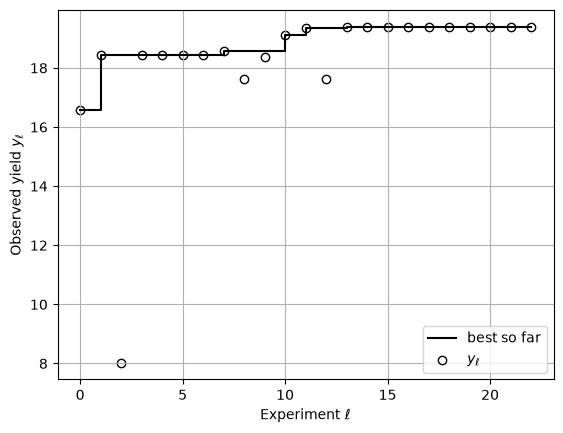

In [2]:
kappa, n_iter = 0.2, 20
bounds = Bounds(-np.ones(3), np.ones(3))
data_u = np.array([[0, 0, 0], [1, 1, 1], [-1, -1, -1]], dtype=float)
data_y = phi(data_u)
# alpha adds a small jitter to the kernel matrix: the yields have no noise, and without it the fit is ill-conditioned
gp = GaussianProcessRegressor(kernel=RBF(length_scale=np.ones(3)), normalize_y=True, alpha=1e-4)

for ell in range(n_iter):
    gp.fit(data_u, data_y)                                        # 1. model from D_ell
    def neg_AF(u):
        m, s = gp.predict(np.atleast_2d(u), return_std=True)
        return -(m[0] + kappa * s[0])                             # AF = m + kappa*sigma (minimize -AF)
    u_new = minimize(neg_AF, data_u[np.argmax(data_y)], method='SLSQP', bounds=bounds).x   # 2. maximize AF
    data_u = np.vstack([data_u, u_new])
    data_y = np.append(data_y, phi(u_new))                        # 3. run the experiment, 4. add it to D

def descale(u, lb=np.array([70, 1, 0.1]), ub=np.array([100, 2, 0.3])):
    """Map [-1, 1] to temperature [C], time [h], concentration [M]."""
    return lb + (u + 1) / 2 * (ub - lb)

best = np.argmax(data_y)
print("best scaled conditions u =", np.round(data_u[best], 3), "  yield =", round(float(data_y[best]), 3))
print("in physical units:", np.round(descale(data_u[best]), 3))

ell = np.arange(len(data_y))
plt.step(ell, np.maximum.accumulate(data_y), 'k-', where='post', label='best so far')
plt.scatter(ell, data_y, color='w', edgecolor='k', label=r'$y_\ell$')
plt.xlabel(r'Experiment $\ell$'); plt.ylabel(r'Observed yield $y_\ell$')
plt.legend(); plt.grid(True)
plt.show()

**The trade-off in numbers.** At the last model, split the acquisition function at three conditions: the best experiment, the center, and an untested corner. The inputs matter in inverse proportion to their length scales $\ell_i$.

In [3]:
for name, u in (("best experiment", data_u[best]), ("center", np.zeros(3)), ("corner (1,-1,-1)", np.array([1.0, -1, -1]))):
    m, s = gp.predict(np.atleast_2d(u), return_std=True)
    print(f"{name:17s}: m = {m[0]:6.2f}, kappa*sigma = {kappa*s[0]:5.3f}, AF = {m[0]+kappa*s[0]:6.2f}   (true yield {phi(u)[0]:.2f})")
print("length scales (temperature, time, concentration):", np.round(gp.kernel_.length_scale, 2))

best experiment  : m =  19.39, kappa*sigma = 0.002, AF =  19.40   (true yield 19.40)
center           : m =  16.58, kappa*sigma = 0.005, AF =  16.58   (true yield 16.58)
corner (1,-1,-1) : m =  16.48, kappa*sigma = 0.292, AF =  16.77   (true yield 15.64)
length scales (temperature, time, concentration): [1.21 1.61 1.21]


**Note:** As in the book, BO balances exploration and exploitation, and the experiment history converges to the best extraction conditions in a few experiments.